In [2]:
import os, gc, re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from pandas.api.types import union_categoricals
from scipy import sparse
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve)
from sklearn.model_selection import train_test_split

try:
    from IPython.display import display
except ImportError:          # allows the code to run as a plain script too
    display = print

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.6f}")

from math import ceil, sqrt

In [3]:
MODELS = {"Random Forest": "random_forest", "XGBoost": "xgboost", "Logistic Regression": "logistic_regression", "LSTM": "lstm"}
COLORS = {"Random Forest": "tab:green", "XGBoost": "tab:red", "Logistic Regression": "tab:blue", "LSTM": "tab:purple"}
THRESHOLDS = [0.50, 0.40, 0.30, 0.20, 0.10]
TARGET_PRECISION, TARGET_RECALL = 0.20, 0.80
TOP_K_FRACTIONS = [0.001, 0.005, 0.01, 0.05]      # "if analysts only review the top 0.1 % / 0.5 % / 1 % / 5 % highest-risk transactions"
AGREEMENT_THRESHOLD = 0.50                         # threshold used for the "which model catches which laundering case" analysis
RUN_BOOTSTRAP = True                               # confidence intervals for ROC-AUC / PR-AUC (takes a few minutes on 1.4M rows)
N_BOOT = 100
RANDOM_STATE = 42


def find_project_root():
    """Walk upwards from the notebook's folder until we find the AML-GNN-Project root
    (the folder that contains data/processed). Works from notebooks/ or models/."""
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "data" / "processed").is_dir():
            return cand
    raise FileNotFoundError("Could not find a folder containing data/processed. "
                            "Open the notebook from inside AML-GNN-Project or set PROJECT_ROOT manually.")

PROJECT_ROOT = find_project_root()          # e.g. PROJECT_ROOT = Path(r"C:/.../AML-GNN-Project")
DATA_RAW       = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
MODELS_DIR     = PROJECT_ROOT / "models"
OUTPUTS_DIR    = PROJECT_ROOT / "outputs"
RESULTS_DIR    = PROJECT_ROOT / "results"
for d in (MODELS_DIR, OUTPUTS_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

PATH_TRANSACTIONS      = DATA_PROCESSED / "transactions.csv"
PATH_TX_FEATURES       = DATA_PROCESSED / "transaction_features.csv"
PATH_ACCOUNT_BEHAVIOUR = DATA_PROCESSED / "account_behaviour.csv"
PATH_TEMPORAL          = DATA_PROCESSED / "temporal_features.csv"
PATH_GRAPH             = DATA_PROCESSED / "graph_features.csv"
PATH_BANKS             = DATA_PROCESSED / "banks.csv"
PATH_ACCOUNTS          = DATA_PROCESSED / "accounts.csv"
PATH_PATTERNS          = DATA_RAW / "LI-Small_Patterns.txt"

print("Project root :", PROJECT_ROOT)
for p in (PATH_TRANSACTIONS, PATH_TX_FEATURES, PATH_ACCOUNT_BEHAVIOUR, PATH_TEMPORAL, PATH_GRAPH, PATH_BANKS, PATH_ACCOUNTS):
    print(f"  {'OK     ' if p.exists() else 'MISSING'} {p.relative_to(PROJECT_ROOT)}")

Project root : E:\AML-GNN-Project
  OK      data\processed\transactions.csv
  OK      data\processed\transaction_features.csv
  OK      data\processed\account_behaviour.csv
  OK      data\processed\temporal_features.csv
  OK      data\processed\graph_features.csv
  OK      data\processed\banks.csv
  OK      data\processed\accounts.csv


In [4]:
preds = {}
for name, slug in MODELS.items():
    p = OUTPUTS_DIR / f"{slug}_predictions.csv"
    if p.exists():
        preds[name] = pd.read_csv(p, usecols=["Transaction ID", "Actual Is Laundering", "AML Risk Score"]).drop_duplicates("Transaction ID").set_index("Transaction ID")
        print(f"[found]   {name:<20} {len(preds[name]):>10,} predictions   <- {p.name}")
    else:
        print(f"[MISSING] {name:<20} {p.name} - run that notebook first")
assert len(preds) >= 2, "Need the prediction files of at least two models (run notebooks 11-14 first)."

# compare ONLY on test transactions that every model scored (normally identical sets)
common = None
for d in preds.values():
    common = d.index if common is None else common.intersection(d.index)
sizes = {k: len(v) for k, v in preds.items()}
if len(set(sizes.values())) > 1 or len(common) != next(iter(sizes.values())):
    print(f"\nWARNING: models were evaluated on different row sets {sizes}. Comparing on the {len(common):,} rows they share.")
common = common.sort_values()
y = preds[next(iter(preds))].loc[common, "Actual Is Laundering"].to_numpy().astype(int)
for name, d in preds.items():
    assert (d.loc[common, "Actual Is Laundering"].to_numpy().astype(int) == y).all(), f"{name}: actual labels differ from the other models"
scores = {name: d.loc[common, "AML Risk Score"].to_numpy(dtype=np.float64) for name, d in preds.items()}
MODEL_NAMES = list(scores)
n, n_pos = len(y), int(y.sum()); prevalence = n_pos / n
print(f"\nCommon test set: {n:,} transactions | laundering {n_pos:,} ({prevalence:.4%}) | normal {n - n_pos:,}")
print("All models are scored on exactly the same rows and the same labels -> a fair comparison.")

[found]   Random Forest         1,384,810 predictions   <- random_forest_predictions.csv
[found]   XGBoost               1,384,810 predictions   <- xgboost_predictions.csv
[found]   Logistic Regression   1,384,810 predictions   <- logistic_regression_predictions.csv
[found]   LSTM                  1,384,810 predictions   <- lstm_predictions.csv

Common test set: 1,384,810 transactions | laundering 925 (0.0668%) | normal 1,383,885
All models are scored on exactly the same rows and the same labels -> a fair comparison.


In [5]:
def confusion_metrics(y_true, score, thr):
    pred = score >= thr
    tp = int((pred & (y_true == 1)).sum()); fp = int((pred & (y_true == 0)).sum())
    fn = int((~pred & (y_true == 1)).sum()); tn = int((~pred & (y_true == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    spec = tn / (tn + fp) if tn + fp else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    denom = sqrt(float(tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    mcc = (tp * tn - fp * fn) / denom if denom else 0.0
    return {"Threshold": thr, "TP": tp, "FP": fp, "FN": fn, "TN": tn, "Flagged": tp + fp,
            "Accuracy": (tp + tn) / len(y_true), "Precision": prec, "Recall": rec, "Specificity": spec,
            "False Positive Rate": 1 - spec, "F1-Score": f1, "Balanced Accuracy": (rec + spec) / 2, "MCC": mcc}

# ---- long table: every model x every threshold ----
rows = []
for name in MODEL_NAMES:
    for t in THRESHOLDS:
        rows.append({"Model": name, **confusion_metrics(y, scores[name], t)})
sweep = pd.DataFrame(rows)
sweep["Meets both targets"] = (sweep["Precision"] >= TARGET_PRECISION) & (sweep["Recall"] >= TARGET_RECALL)
sweep.to_csv(RESULTS_DIR / "baseline_threshold_comparison.csv", index=False)

# ---- threshold-free (ranking) metrics ----
rank_rows = []
for name in MODEL_NAMES:
    s = scores[name]
    p, r, t = precision_recall_curve(y, s)
    f1_curve = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    best = int(np.argmax(f1_curve))
    ok = r[:-1] >= TARGET_RECALL
    row = {"Model": name, "ROC-AUC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s),
           "PR-AUC lift vs no-skill": average_precision_score(y, s) / prevalence,
           "Best F1 (any threshold)": f1_curve[best], "Threshold of best F1": t[best],
           f"Best precision at recall >= {TARGET_RECALL:.0%}": p[:-1][ok].max() if ok.any() else np.nan,
           "Max risk score": s.max(), "Mean risk score": s.mean()}
    order = np.argsort(-s, kind="stable")
    for frac in TOP_K_FRACTIONS:
        k = max(int(ceil(frac * n)), 1)
        hits = int(y[order[:k]].sum())
        row[f"Recall @ top {frac:.1%}"] = hits / n_pos
        row[f"Precision @ top {frac:.1%}"] = hits / k
    rank_rows.append(row)
ranking = pd.DataFrame(rank_rows)

print("1) THRESHOLD-FREE metrics (how well each model RANKS laundering above normal). No-skill PR-AUC = prevalence = %.5f" % prevalence)
display(ranking.set_index("Model").T)
print("\n2) METRICS AT THE DEFAULT THRESHOLD 0.50")
at50 = sweep[sweep["Threshold"] == 0.50].set_index("Model")
display(at50[["TP", "FP", "FN", "TN", "Flagged", "Accuracy", "Precision", "Recall", "Specificity", "F1-Score", "Balanced Accuracy", "MCC"]])
print("\n3) EVERY MODEL AT EVERY THRESHOLD")
for t in THRESHOLDS:
    print(f"\n--- threshold {t:.2f} ---")
    display(sweep[sweep["Threshold"] == t].set_index("Model")[["TP", "FP", "FN", "TN", "Flagged", "Precision", "Recall", "F1-Score", "MCC", "Meets both targets"]])

1) THRESHOLD-FREE metrics (how well each model RANKS laundering above normal). No-skill PR-AUC = prevalence = 0.00067


Model,Random Forest,XGBoost,Logistic Regression,LSTM
ROC-AUC,0.973369,0.970416,0.970093,0.963927
PR-AUC,0.055739,0.163093,0.033301,0.151973
PR-AUC lift vs no-skill,83.446245,244.164730,49.854340,227.518230
Best F1 (any threshold),0.124671,0.220994,0.093458,0.227701
Threshold of best F1,0.809948,0.987169,0.993524,0.996332
Best precision at recall >= 80%,0.009934,0.013990,0.009094,0.007234
Max risk score,0.987380,0.999604,0.999979,0.999990
Mean risk score,0.041002,0.017774,0.133890,0.155487
Recall @ top 0.1%,0.153514,0.263784,0.091892,0.248649
Precision @ top 0.1%,0.102527,0.176173,0.061372,0.166065



2) METRICS AT THE DEFAULT THRESHOLD 0.50


,TP,FP,FN,TN,Flagged,Accuracy,Precision,Recall,Specificity,F1-Score,Balanced Accuracy,MCC
Model,,,,,,,,,,,,
Random Forest,533,13036,392,1370849,13569,0.990303,0.039281,0.576216,0.990580,0.073548,0.783398,0.148668
XGBoost,625,13099,300,1370786,13724,0.990324,0.045541,0.675676,0.990535,0.085330,0.833105,0.173764
Logistic Regression,900,187623,25,1196262,188523,0.864495,0.004774,0.972973,0.864423,0.009501,0.918698,0.063089
LSTM,912,245113,13,1138772,246025,0.822989,0.003707,0.985946,0.822881,0.007386,0.904413,0.054672



3) EVERY MODEL AT EVERY THRESHOLD

--- threshold 0.50 ---


...

,TP,FP,FN,TN,Flagged,Precision,Recall,F1-Score,MCC,Meets both targets
Model,,,,,,,,,,
Random Forest,692,47298,233,1336587,47990,0.014420,0.748108,0.028294,0.100847,False
XGBoost,674,21151,251,1362734,21825,0.030882,0.728649,0.059253,0.147982,False
Logistic Regression,919,235983,6,1147902,236902,0.003879,0.993514,0.007728,0.056465,False
LSTM,917,264662,8,1119223,265579,0.003453,0.991351,0.006882,0.052506,False



--- threshold 0.20 ---


,TP,FP,FN,TN,Flagged,Precision,Recall,F1-Score,MCC,Meets both targets
Model,,,,,,,,,,
Random Forest,814,109353,111,1274532,110167,0.007389,0.880000,0.014655,0.076476,False
XGBoost,698,30431,227,1353454,31129,0.022423,0.754595,0.043552,0.127688,False
Logistic Regression,922,263874,3,1120011,264796,0.003482,0.996757,0.006940,0.052958,False
LSTM,920,282255,5,1101630,283175,0.003249,0.994595,0.006477,0.050647,False



--- threshold 0.10 ---


,TP,FP,FN,TN,Flagged,Precision,Recall,F1-Score,MCC,Meets both targets
Model,,,,,,,,,,
Random Forest,907,180586,18,1203299,181493,0.004997,0.980541,0.009944,0.065080,False
XGBoost,741,53070,184,1330815,53811,0.013770,0.801081,0.027075,0.101969,False
Logistic Regression,923,307520,2,1076365,308443,0.002992,0.997838,0.005967,0.048162,False
LSTM,922,313876,3,1070009,314798,0.002929,0.996757,0.005841,0.047465,False


In [6]:
# Consistency check: the metrics computed here should equal what each model notebook saved in results/<model>_metrics.csv
for name, slug in MODELS.items():
    f = RESULTS_DIR / f"{slug}_metrics.csv"
    if name in scores and f.exists():
        saved = pd.read_csv(f)
        if "Threshold" in saved.columns and "F1-Score" in saved.columns:
            m = saved.merge(sweep[sweep["Model"] == name][["Threshold", "F1-Score", "TP"]], on="Threshold", suffixes=("_saved", "_here"))
            if len(m) and len(common) == int(saved["Test Rows"].iloc[0]):
                print(f"{name:<20} max |F1 difference| vs saved file: {np.abs(m['F1-Score_saved'] - m['F1-Score_here']).max():.2e}   (TP match: {bool((m['TP_saved'] == m['TP_here']).all())})")
            else:
                print(f"{name:<20} saved metrics file covers a different row set - skipped")

Random Forest        max |F1 difference| vs saved file: 5.45e-08   (TP match: True)
XGBoost              max |F1 difference| vs saved file: 5.55e-17   (TP match: True)
Logistic Regression  max |F1 difference| vs saved file: 3.86e-08   (TP match: True)
LSTM                 max |F1 difference| vs saved file: 9.71e-17   (TP match: True)


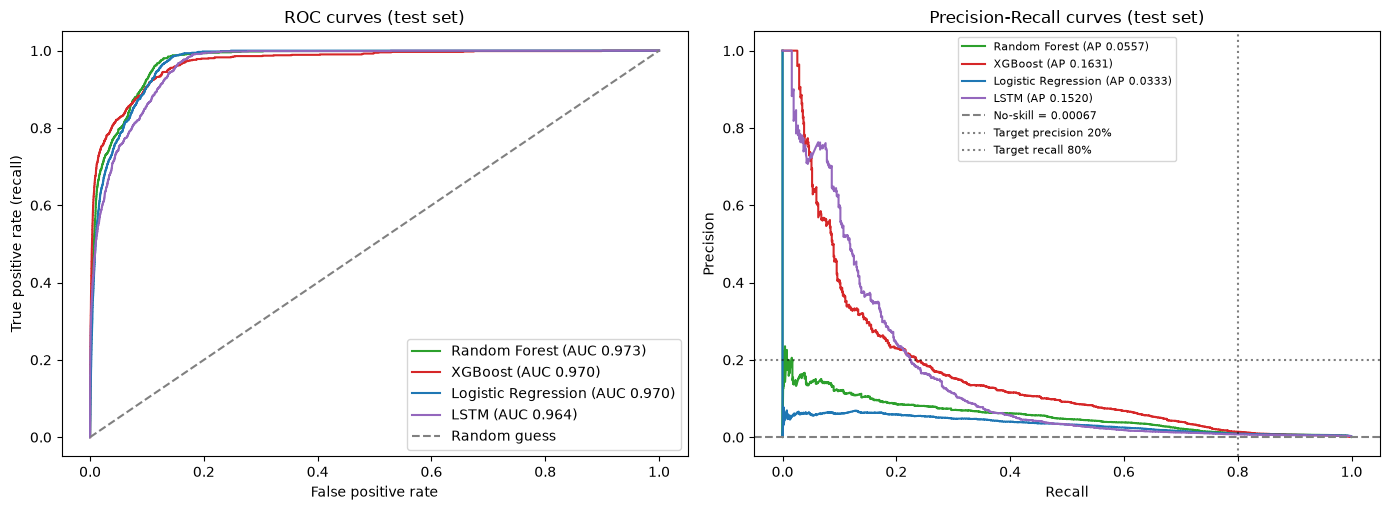

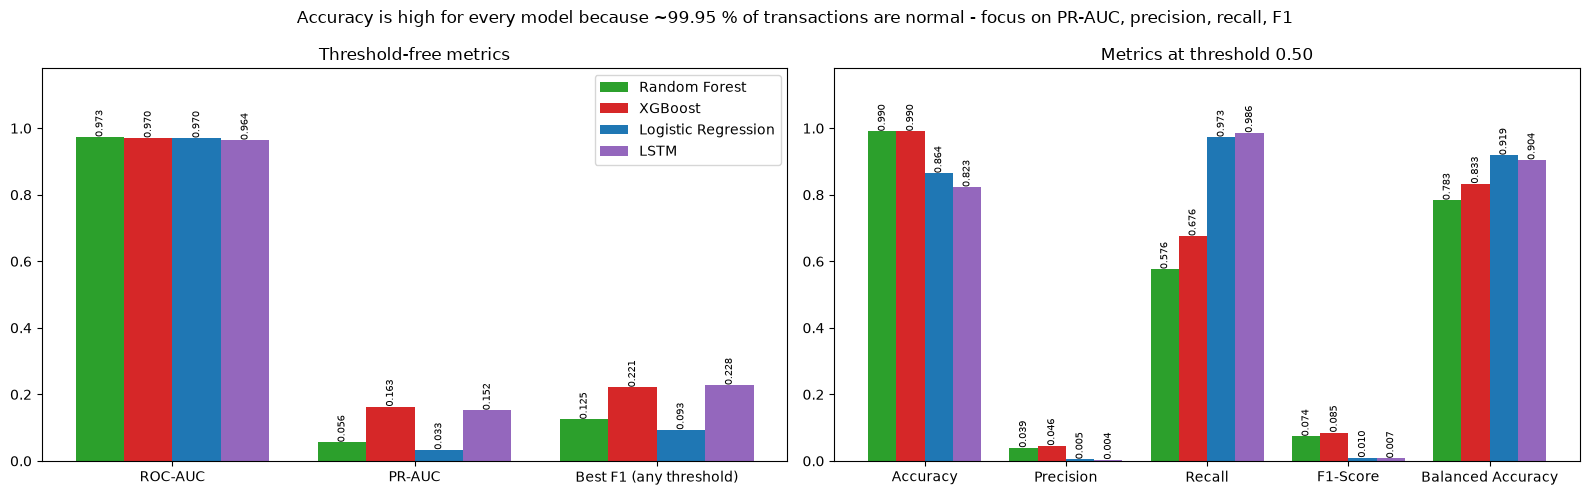

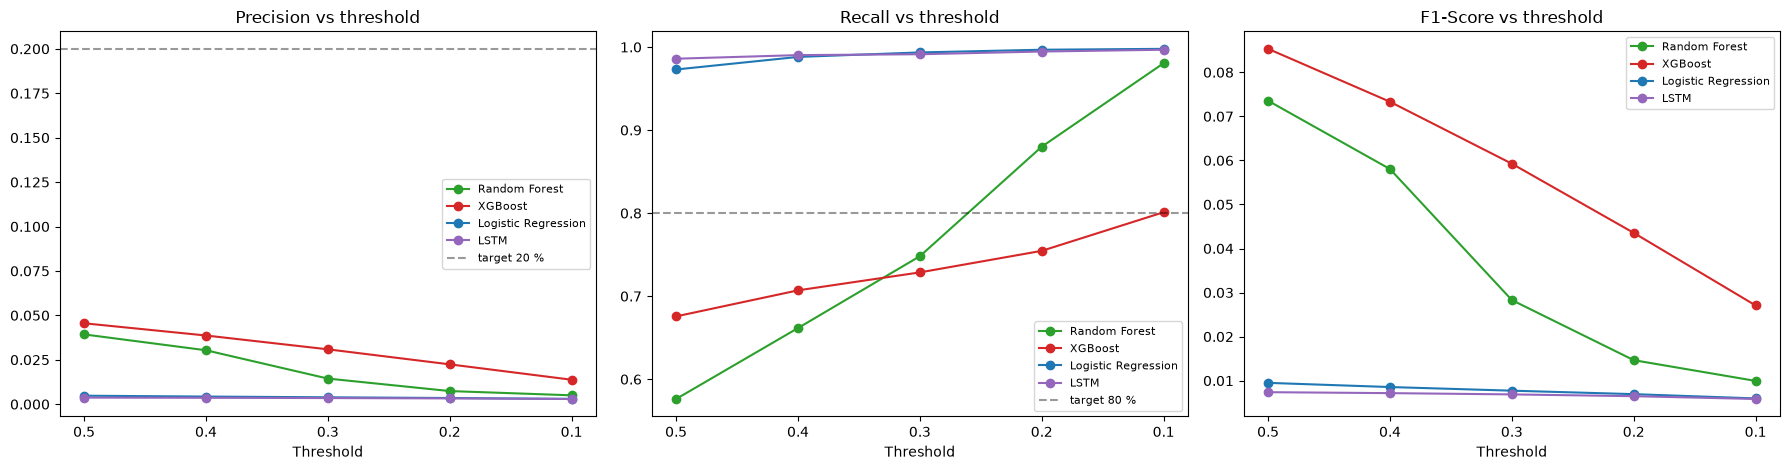

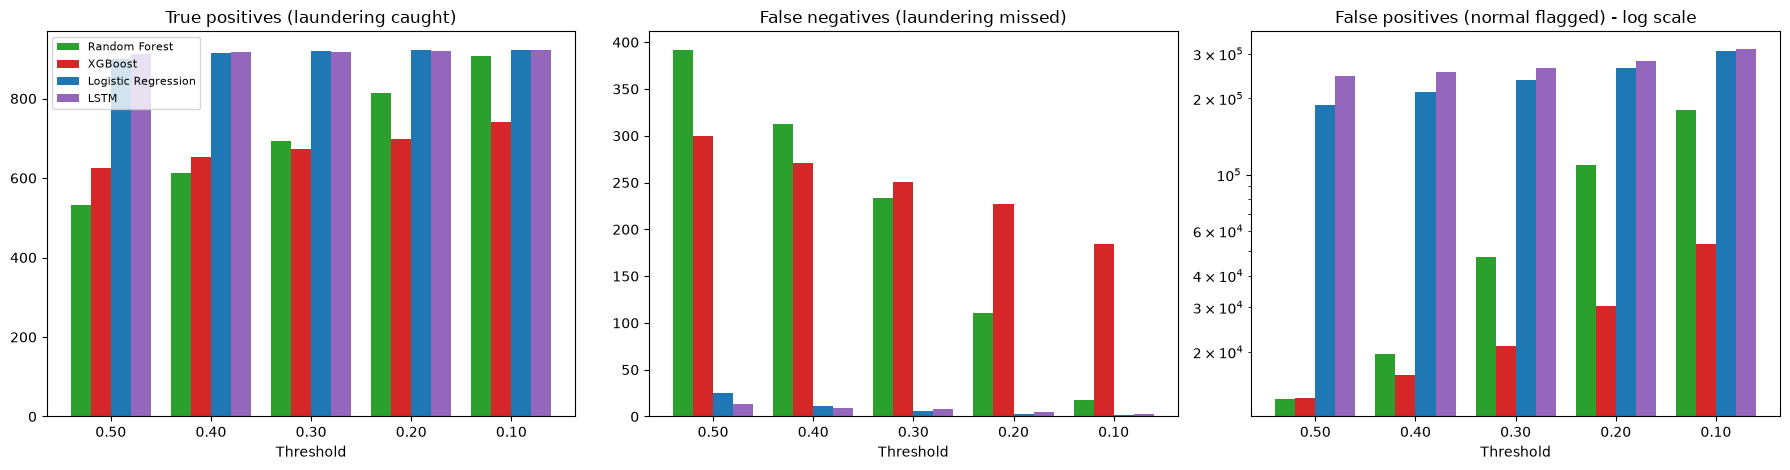

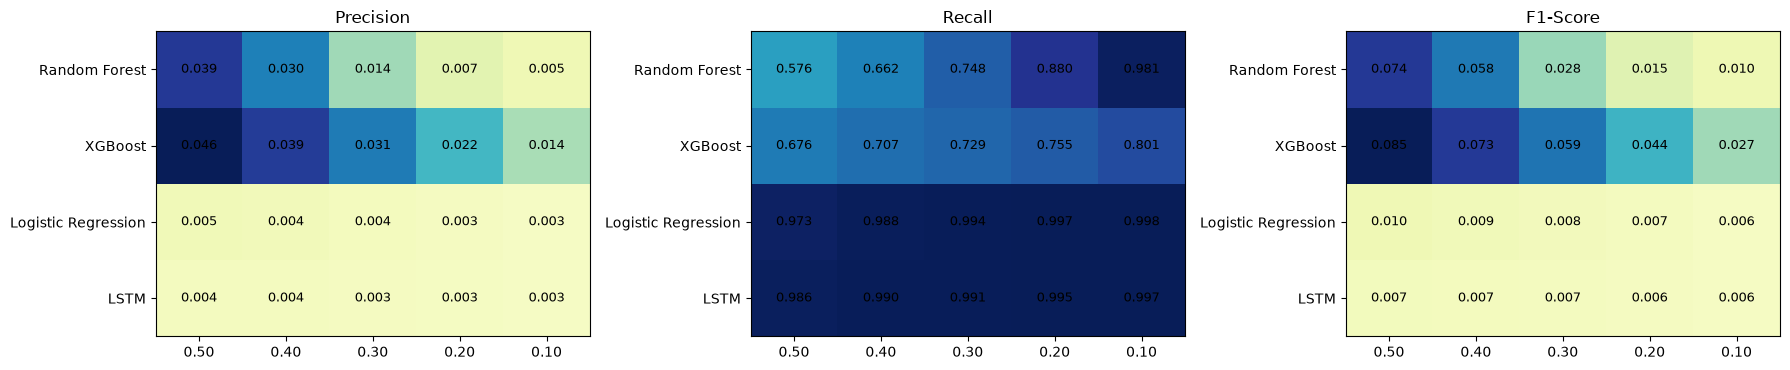

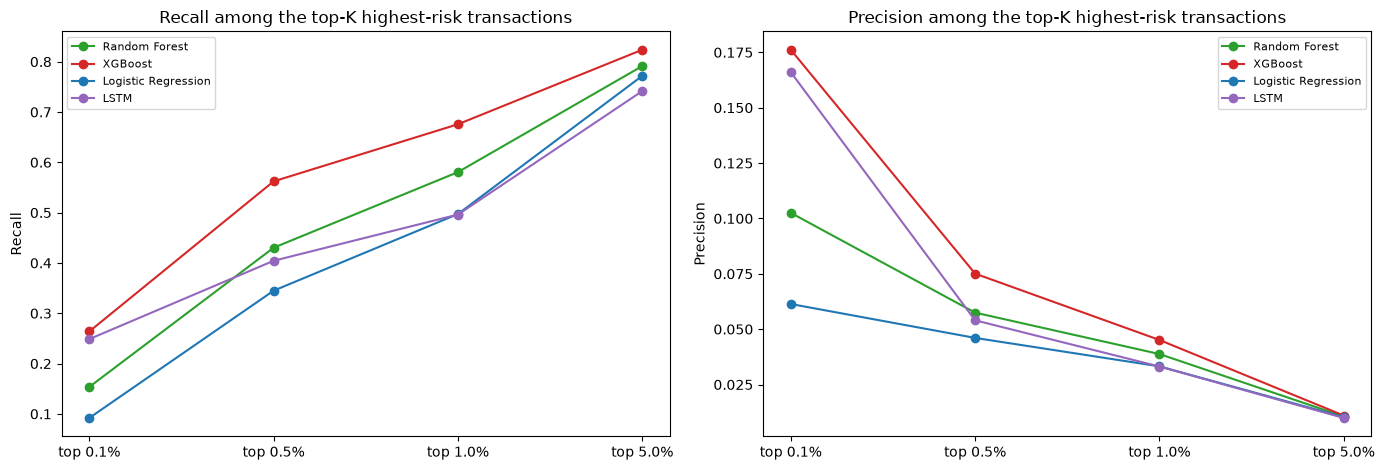

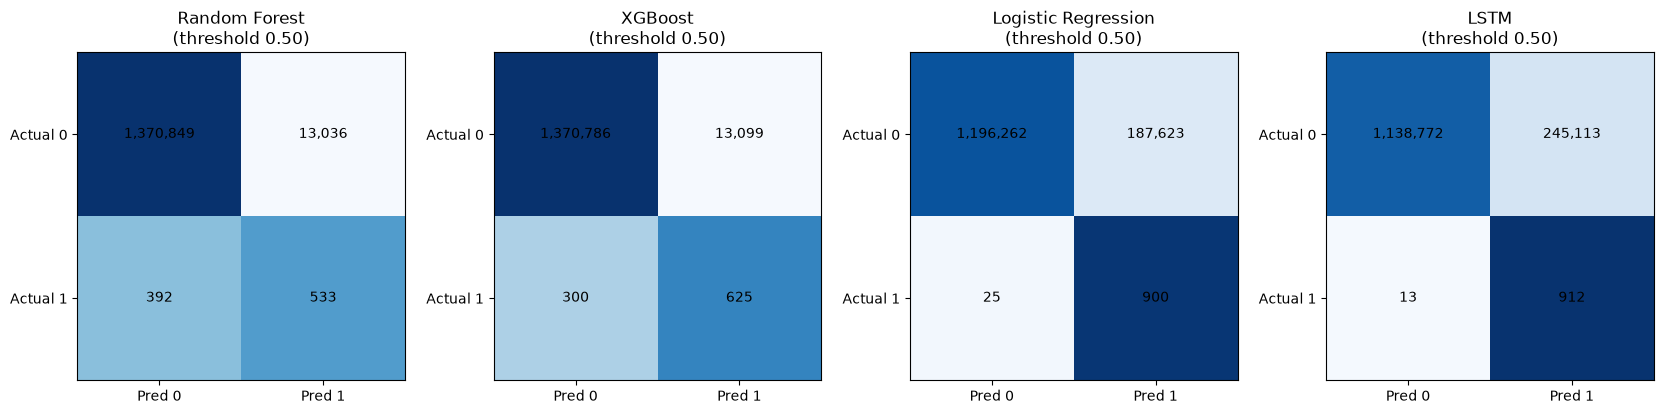

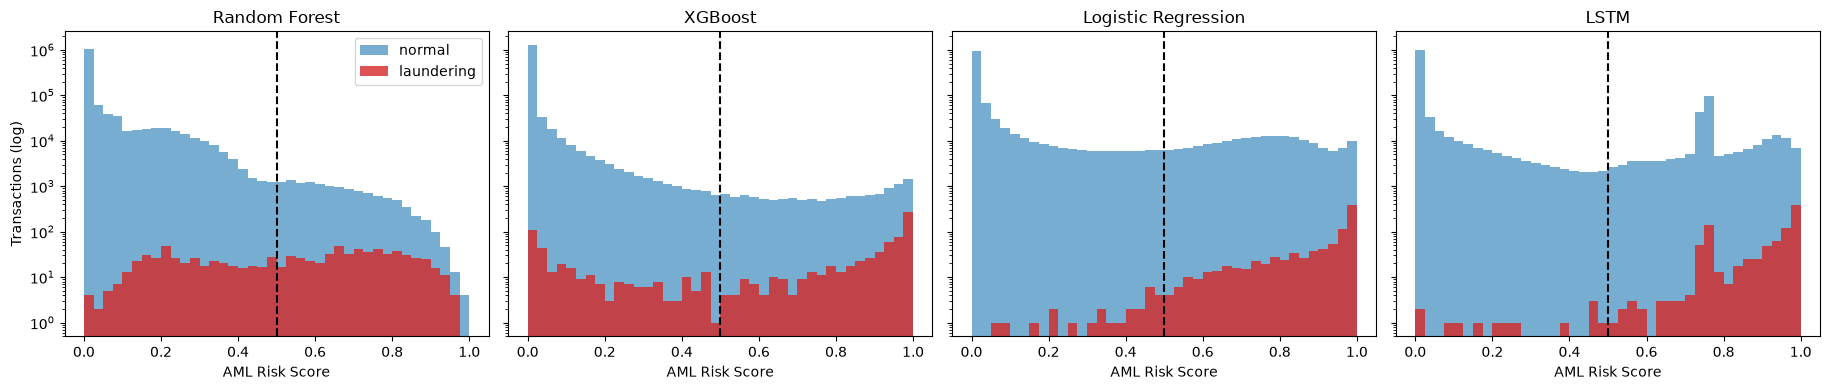

In [7]:
# ---------- ROC and PR curves ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for name in MODEL_NAMES:
    fpr, tpr, _ = roc_curve(y, scores[name]); axes[0].plot(fpr, tpr, color=COLORS[name], label=f"{name} (AUC {roc_auc_score(y, scores[name]):.3f})")
    p, r, _ = precision_recall_curve(y, scores[name]); axes[1].plot(r, p, color=COLORS[name], label=f"{name} (AP {average_precision_score(y, scores[name]):.4f})")
axes[0].plot([0, 1], [0, 1], "--", color="grey", label="Random guess"); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curves (test set)"); axes[0].legend()
axes[1].axhline(prevalence, ls="--", color="grey", label=f"No-skill = {prevalence:.5f}")
axes[1].axhline(TARGET_PRECISION, ls=":", color="black", alpha=0.5, label=f"Target precision {TARGET_PRECISION:.0%}")
axes[1].axvline(TARGET_RECALL, ls=":", color="black", alpha=0.5, label=f"Target recall {TARGET_RECALL:.0%}")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-Recall curves (test set)"); axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "baseline_comparison_roc_pr.png", dpi=150); plt.show()

# ---------- bar charts: threshold-free metrics and metrics at 0.50 ----------
def grouped_bars(ax, table, metrics, title, log=False):
    x = np.arange(len(metrics)); w = 0.8 / len(table)
    for i, (name, row) in enumerate(table.iterrows()):
        vals = [row[m] for m in metrics]
        ax.bar(x + i * w - 0.4 + w / 2, vals, w, color=COLORS[name], label=name)
        for xi, v in zip(x + i * w - 0.4 + w / 2, vals):
            ax.text(xi, v, f"{v:.3f}", ha="center", va="bottom", fontsize=7, rotation=90)
    ax.set_xticks(x); ax.set_xticklabels(metrics); ax.set_title(title); ax.set_ylim(0, 1.18 if not log else None)
    if log: ax.set_yscale("log")
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
grouped_bars(axes[0], ranking.set_index("Model"), ["ROC-AUC", "PR-AUC", "Best F1 (any threshold)"], "Threshold-free metrics")
grouped_bars(axes[1], at50, ["Accuracy", "Precision", "Recall", "F1-Score", "Balanced Accuracy"], "Metrics at threshold 0.50")
axes[0].legend(); fig.suptitle("Accuracy is high for every model because ~99.95 % of transactions are normal - focus on PR-AUC, precision, recall, F1")
fig.tight_layout(); fig.savefig(RESULTS_DIR / "baseline_comparison_metric_bars.png", dpi=150); plt.show()

# ---------- effect of the threshold, per model ----------
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, metric in zip(axes, ["Precision", "Recall", "F1-Score"]):
    for name in MODEL_NAMES:
        d = sweep[sweep["Model"] == name].sort_values("Threshold")
        ax.plot(d["Threshold"], d[metric], marker="o", color=COLORS[name], label=name)
    if metric == "Precision": ax.axhline(TARGET_PRECISION, ls="--", color="black", alpha=0.4, label="target 20 %")
    if metric == "Recall": ax.axhline(TARGET_RECALL, ls="--", color="black", alpha=0.4, label="target 80 %")
    ax.set_xlabel("Threshold"); ax.set_title(f"{metric} vs threshold"); ax.set_xticks(THRESHOLDS); ax.invert_xaxis(); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "baseline_comparison_threshold_curves.png", dpi=150); plt.show()

# ---------- TP / FP / FN per threshold ----------
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, metric, title, log in zip(axes, ["TP", "FN", "FP"], ["True positives (laundering caught)", "False negatives (laundering missed)", "False positives (normal flagged) - log scale"], [False, False, True]):
    w = 0.8 / len(MODEL_NAMES)
    for i, name in enumerate(MODEL_NAMES):
        d = sweep[sweep["Model"] == name].set_index("Threshold").loc[THRESHOLDS]
        ax.bar(np.arange(len(THRESHOLDS)) + i * w - 0.4 + w / 2, d[metric], w, color=COLORS[name], label=name)
    ax.set_xticks(np.arange(len(THRESHOLDS))); ax.set_xticklabels([f"{t:.2f}" for t in THRESHOLDS]); ax.set_xlabel("Threshold"); ax.set_title(title)
    if log: ax.set_yscale("log")
axes[0].legend(fontsize=8); fig.tight_layout(); fig.savefig(RESULTS_DIR / "baseline_comparison_tp_fp_fn.png", dpi=150); plt.show()

# ---------- heatmaps model x threshold ----------
fig, axes = plt.subplots(1, 3, figsize=(18, 3.8))
for ax, metric in zip(axes, ["Precision", "Recall", "F1-Score"]):
    piv = sweep.pivot(index="Model", columns="Threshold", values=metric).loc[MODEL_NAMES, THRESHOLDS]
    ax.imshow(piv.to_numpy(), cmap="YlGnBu", vmin=0, vmax=max(piv.to_numpy().max(), 1e-9), aspect="auto")
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            ax.text(j, i, f"{piv.iloc[i, j]:.3f}", ha="center", va="center", fontsize=9)
    ax.set_xticks(range(len(THRESHOLDS))); ax.set_xticklabels([f"{t:.2f}" for t in THRESHOLDS]); ax.set_yticks(range(len(MODEL_NAMES))); ax.set_yticklabels(MODEL_NAMES); ax.set_title(metric)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "baseline_comparison_heatmaps.png", dpi=150); plt.show()

# ---------- if analysts review only the top-K highest-risk transactions ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, kind in zip(axes, ["Recall", "Precision"]):
    for name in MODEL_NAMES:
        r_ = ranking.set_index("Model").loc[name]
        ax.plot([f"top {f:.1%}" for f in TOP_K_FRACTIONS], [r_[f"{kind} @ top {f:.1%}"] for f in TOP_K_FRACTIONS], marker="o", color=COLORS[name], label=name)
    ax.set_title(f"{kind} among the top-K highest-risk transactions"); ax.set_ylabel(kind); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "baseline_comparison_top_k.png", dpi=150); plt.show()

# ---------- confusion matrices at 0.50 ----------
fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(4.2 * len(MODEL_NAMES), 4))
for ax, name in zip(np.atleast_1d(axes), MODEL_NAMES):
    r_ = at50.loc[name]; cm = np.array([[r_["TN"], r_["FP"]], [r_["FN"], r_["TP"]]], dtype=float)
    ax.imshow(cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None), cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{int(cm[i, j]):,}", ha="center", va="center")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(["Pred 0", "Pred 1"]); ax.set_yticklabels(["Actual 0", "Actual 1"]); ax.set_title(f"{name}\n(threshold 0.50)")
fig.tight_layout(); fig.savefig(RESULTS_DIR / "baseline_comparison_confusion_matrices.png", dpi=150); plt.show()

# ---------- risk-score distributions ----------
fig, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(4.6 * len(MODEL_NAMES), 4), sharey=True)
bins = np.linspace(0, 1, 41)
for ax, name in zip(np.atleast_1d(axes), MODEL_NAMES):
    s = scores[name]
    ax.hist(s[y == 0], bins=bins, alpha=0.6, color="tab:blue", label="normal"); ax.hist(s[y == 1], bins=bins, alpha=0.8, color="tab:red", label="laundering")
    ax.axvline(0.5, color="black", ls="--"); ax.set_yscale("log"); ax.set_title(name); ax.set_xlabel("AML Risk Score")
np.atleast_1d(axes)[0].set_ylabel("Transactions (log)"); np.atleast_1d(axes)[0].legend()
fig.tight_layout(); fig.savefig(RESULTS_DIR / "baseline_comparison_risk_distributions.png", dpi=150); plt.show()

Laundering transactions in the test set: 925   (threshold 0.50)


,Laundering transactions,% of laundering
caught by 0 model(s),5,0.540541
caught by 1 model(s),21,2.270270
caught by 2 model(s),253,27.351351
caught by 3 model(s),141,15.243243
caught by 4 model(s),505,54.594595


Caught ONLY by this model: {'Random Forest': 0, 'XGBoost': 0, 'Logistic Regression': 4, 'LSTM': 17}


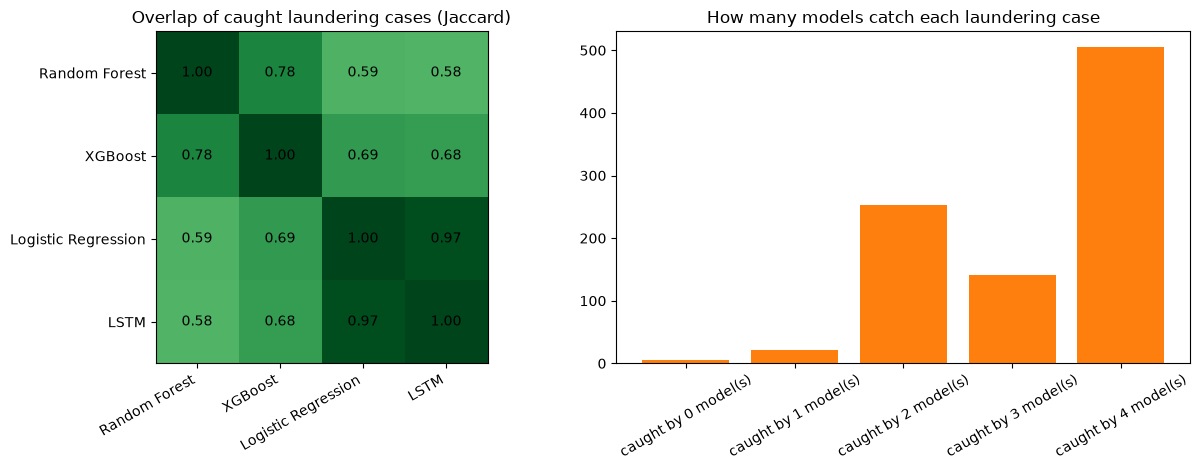

Spearman rank correlation of the models' risk scores (how similarly they order transactions):


,Random Forest,XGBoost,Logistic Regression,LSTM
Random Forest,1.000000,0.490704,0.512809,0.617969
XGBoost,0.490704,1.000000,0.600833,0.450886
Logistic Regression,0.512809,0.600833,1.000000,0.618638
LSTM,0.617969,0.450886,0.618638,1.000000


In [8]:
# Which laundering transactions does each model catch at the chosen threshold, and do the models catch the same ones?
flag = np.column_stack([(scores[nm][y == 1] >= AGREEMENT_THRESHOLD) for nm in MODEL_NAMES])
caught_by = flag.sum(axis=1)
print(f"Laundering transactions in the test set: {n_pos:,}   (threshold {AGREEMENT_THRESHOLD:.2f})")
dist = pd.Series(caught_by).value_counts().reindex(range(len(MODEL_NAMES) + 1), fill_value=0).rename("Laundering transactions")
dist.index = [f"caught by {k} model(s)" for k in dist.index]
display(dist.to_frame().assign(**{"% of laundering": 100 * dist / n_pos}))

uniq = {nm: int(((flag[:, i]) & (caught_by == 1)).sum()) for i, nm in enumerate(MODEL_NAMES)}
print("Caught ONLY by this model:", uniq)
jac = np.zeros((len(MODEL_NAMES), len(MODEL_NAMES)))
for i in range(len(MODEL_NAMES)):
    for j in range(len(MODEL_NAMES)):
        union = (flag[:, i] | flag[:, j]).sum(); jac[i, j] = (flag[:, i] & flag[:, j]).sum() / union if union else 0
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].imshow(jac, cmap="Greens", vmin=0, vmax=1)
for i in range(len(MODEL_NAMES)):
    for j in range(len(MODEL_NAMES)):
        axes[0].text(j, i, f"{jac[i, j]:.2f}", ha="center", va="center")
axes[0].set_xticks(range(len(MODEL_NAMES))); axes[0].set_xticklabels(MODEL_NAMES, rotation=30, ha="right"); axes[0].set_yticks(range(len(MODEL_NAMES))); axes[0].set_yticklabels(MODEL_NAMES)
axes[0].set_title("Overlap of caught laundering cases (Jaccard)")
axes[1].bar(dist.index, dist.values, color="tab:orange"); axes[1].set_title("How many models catch each laundering case"); axes[1].tick_params(axis="x", rotation=30)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "baseline_comparison_agreement.png", dpi=150); plt.show()
sc = pd.DataFrame(scores)
print("Spearman rank correlation of the models' risk scores (how similarly they order transactions):")
display(sc.sample(min(200_000, len(sc)), random_state=RANDOM_STATE).corr(method="spearman"))

temporal_features.csv: all 15 expected columns present (3 identifiers + 12 numeric temporal columns).
Test transactions found in temporal_features.csv: 100.00%
Test rows that are the sender's FIRST transaction (Time Since Previous is blank): 0.20% | laundering share among them: 1.0619% vs 0.0648% for the rest

1) Each temporal column used ALONE as a risk score (0.5 = no information):


,ROC-AUC (single feature),Strength |AUC - 0.5|,Direction,PR-AUC (best direction)
Temporal feature,,,,
Transactions Last 7 Days,0.368515,0.131485,lower = riskier,0.001944
Account Age Before Transaction,0.620707,0.120707,higher = riskier,0.083512
Transactions Since First Seen,0.387804,0.112196,lower = riskier,0.001862
Transactions Last 30 Minutes,0.390098,0.109902,lower = riskier,0.000993
Transactions Last 24 Hours,0.391524,0.108476,lower = riskier,0.001283
Transactions Last 1 Hour,0.394687,0.105313,lower = riskier,0.000990
Average Amount Last 24 Hours,0.403590,0.096410,lower = riskier,0.001259
Amount Last 24 Hours,0.410197,0.089803,lower = riskier,0.001252
Transactions Last 10 Minutes,0.450753,0.049247,lower = riskier,0.000840


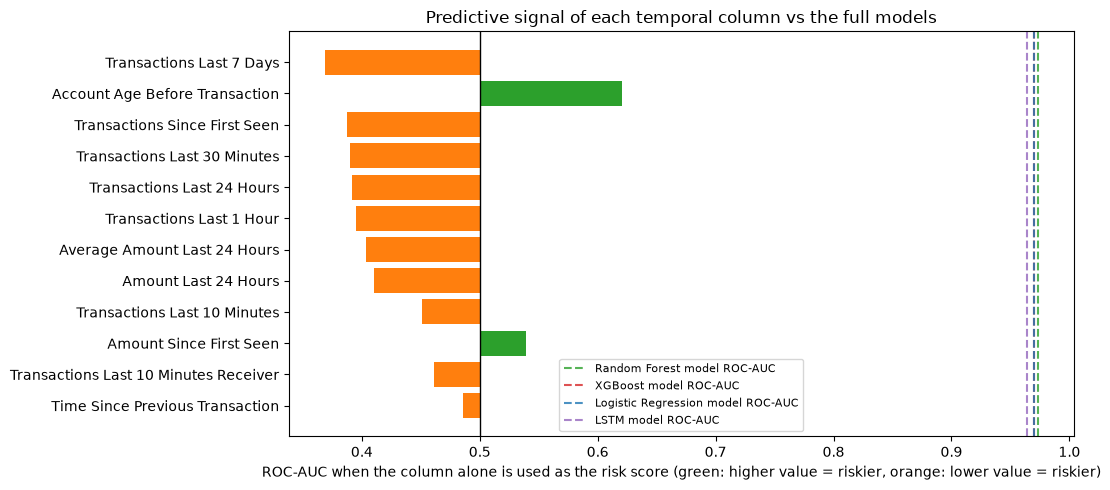


2) Reliance of the tabular models on the temporal columns:


,Share of total importance on temporal columns,Number of temporal columns in the model's top 10
Random Forest,0.260912,3.000000
XGBoost,0.095575,1.000000
Logistic Regression,0.206069,1.000000


,Random Forest,XGBoost,Logistic Regression
Transactions Last 10 Minutes,0.0147,0.0029,0.0126
Transactions Last 30 Minutes,0.0341,0.0223,0.0549
Transactions Last 1 Hour,0.0288,0.0261,0.0173
Transactions Last 24 Hours,0.0294,0.0048,0.0001
Transactions Last 7 Days,0.0152,0.0029,0.0145
Amount Last 24 Hours,0.0161,0.0033,0.0229
Time Since Previous Transaction,0.0482,0.0100,0.0028
Account Age Before Transaction,0.0252,0.0036,0.0142
Transactions Since First Seen,0.0129,0.0063,0.0320
Amount Since First Seen,0.0135,0.0041,0.0047


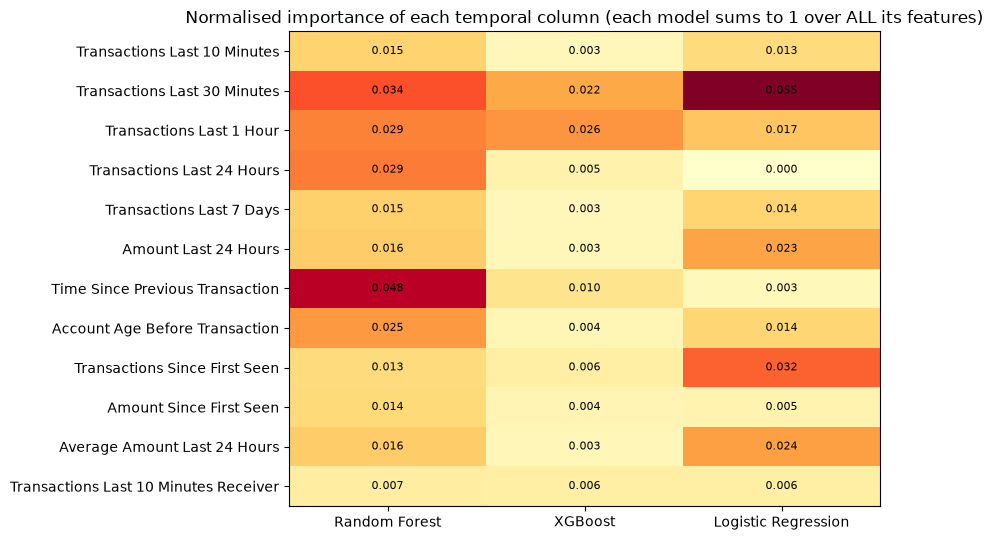

Note: importances are not comparable across model types in absolute size (impurity vs |coefficient|); compare the pattern, not the number.
The LSTM uses all 12 temporal columns as per-step inputs but has no feature-importance output.


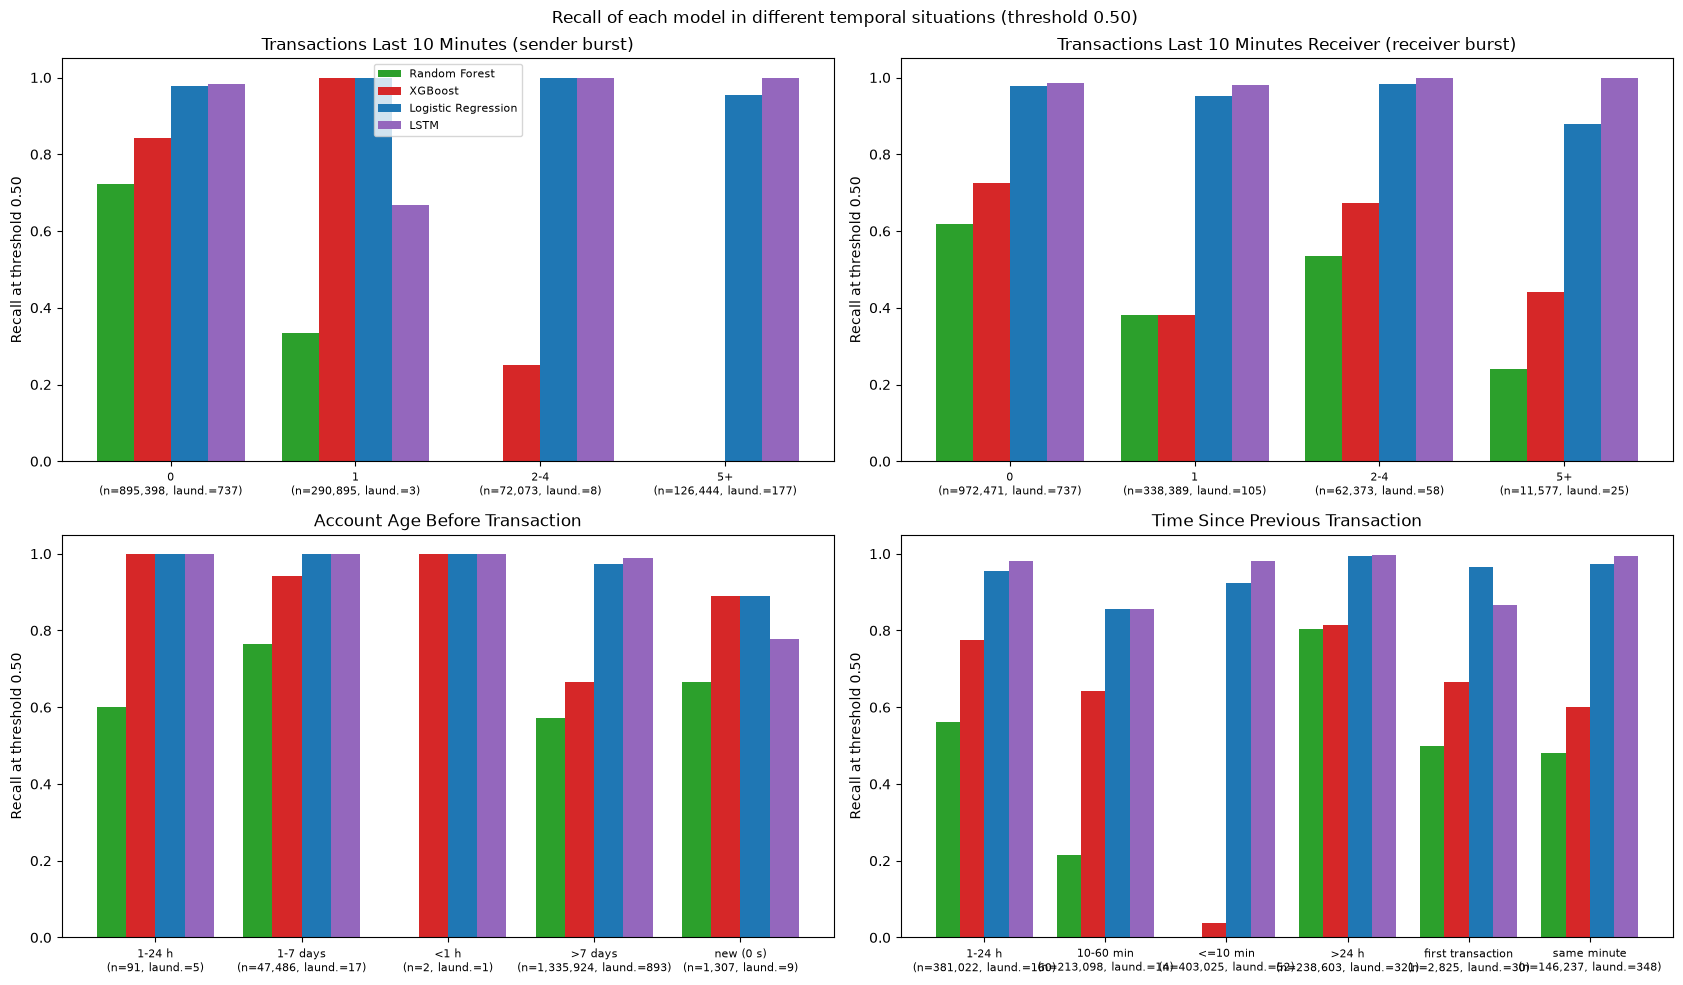

3) Laundering share and model results per temporal situation (threshold 0.50):

--- Transactions Last 10 Minutes (sender burst) ---


,Rows,Laundering,Laundering %,Recall - Random Forest,Recall - XGBoost,Recall - Logistic Regression,Recall - LSTM
Group,,,,,,,
0,895398,737,0.082310,0.721845,0.841248,0.976934,0.983718
1,290895,3,0.001031,0.333333,1.000000,1.000000,0.666667
2-4,72073,8,0.011100,0.000000,0.250000,1.000000,1.000000
5+,126444,177,0.139983,0.000000,0.000000,0.954802,1.000000



--- Transactions Last 10 Minutes Receiver (receiver burst) ---


,Rows,Laundering,Laundering %,Recall - Random Forest,Recall - XGBoost,Recall - Logistic Regression,Recall - LSTM
Group,,,,,,,
0,972471,737,0.075786,0.618725,0.725916,0.978290,0.985075
1,338389,105,0.031029,0.380952,0.380952,0.952381,0.980952
2-4,62373,58,0.092989,0.534483,0.672414,0.982759,1.000000
5+,11577,25,0.215945,0.240000,0.440000,0.880000,1.000000



--- Account Age Before Transaction ---


,Rows,Laundering,Laundering %,Recall - Random Forest,Recall - XGBoost,Recall - Logistic Regression,Recall - LSTM
Group,,,,,,,
1-24 h,91,5,5.494505,0.600000,1.000000,1.000000,1.000000
1-7 days,47486,17,0.035800,0.764706,0.941176,1.000000,1.000000
<1 h,2,1,50.000000,0.000000,1.000000,1.000000,1.000000
>7 days,1335924,893,0.066845,0.572228,0.666293,0.973124,0.987682
new (0 s),1307,9,0.688600,0.666667,0.888889,0.888889,0.777778



--- Time Since Previous Transaction ---


,Rows,Laundering,Laundering %,Recall - Random Forest,Recall - XGBoost,Recall - Logistic Regression,Recall - LSTM
Group,,,,,,,
1-24 h,381022,160,0.041992,0.562500,0.775000,0.956250,0.981250
10-60 min,213098,14,0.006570,0.214286,0.642857,0.857143,0.857143
<=10 min,403025,52,0.012902,0.000000,0.038462,0.923077,0.980769
>24 h,238603,321,0.134533,0.803738,0.813084,0.993769,0.996885
first transaction,2825,30,1.061947,0.500000,0.666667,0.966667,0.866667
same minute,146237,348,0.237970,0.479885,0.600575,0.974138,0.994253


Reading guide: a group with a much higher laundering share than the average is a risky temporal pattern; a model with low recall there is missing it.


In [9]:
# =====================================================================================
# TEMPORAL FEATURE ANALYSIS - uses ALL columns of the new data/processed/temporal_features.csv (15 columns, notebook 09)
# =====================================================================================
TEMPORAL_ID_COLS = ["Transaction ID", "Sender Account ID", "Receiver Account ID"]
TEMPORAL_COLS = ["Transactions Last 10 Minutes", "Transactions Last 30 Minutes", "Transactions Last 1 Hour", "Transactions Last 24 Hours", "Transactions Last 7 Days",
                 "Amount Last 24 Hours", "Time Since Previous Transaction", "Account Age Before Transaction", "Transactions Since First Seen",
                 "Amount Since First Seen", "Average Amount Last 24 Hours", "Transactions Last 10 Minutes Receiver"]
hdr = list(pd.read_csv(PATH_TEMPORAL, nrows=0).columns)
missing_cols = [c for c in TEMPORAL_ID_COLS + TEMPORAL_COLS if c not in hdr]
if missing_cols:
    raise ValueError(f"temporal_features.csv is missing {missing_cols} - it looks like the OLD 8-column file. Run notebook 09 first, then re-run notebooks 11-14.")
print(f"temporal_features.csv: all {len(hdr)} expected columns present (3 identifiers + {len(TEMPORAL_COLS)} numeric temporal columns).")

tmp = pd.read_csv(PATH_TEMPORAL, usecols=["Transaction ID"] + TEMPORAL_COLS, dtype={"Transaction ID": "int64", **{c: "float64" for c in TEMPORAL_COLS}})
tmp = tmp.drop_duplicates("Transaction ID").set_index("Transaction ID").reindex(common)
coverage = tmp[TEMPORAL_COLS[0]].notna().mean()
print(f"Test transactions found in temporal_features.csv: {coverage:.2%}" + ("" if coverage > 0.999 else "   <-- WARNING: some test rows have no temporal features"))
first_txn = tmp["Time Since Previous Transaction"].isna().to_numpy()     # NaN = the sender's first transaction
print(f"Test rows that are the sender's FIRST transaction (Time Since Previous is blank): {first_txn.mean():.2%} | laundering share among them: {y[first_txn].mean():.4%} vs {y[~first_txn].mean():.4%} for the rest")

# ---------- 1. how informative is each temporal column on its own? ----------
rows = []
for col in TEMPORAL_COLS:
    v = tmp[col].fillna(-1).to_numpy(dtype=float)
    auc = roc_auc_score(y, v)
    rows.append({"Temporal feature": col, "ROC-AUC (single feature)": auc, "Strength |AUC - 0.5|": abs(auc - 0.5),
                 "Direction": "higher = riskier" if auc >= 0.5 else "lower = riskier",
                 "PR-AUC (best direction)": max(average_precision_score(y, v), average_precision_score(y, -v))})
single = pd.DataFrame(rows).sort_values("Strength |AUC - 0.5|", ascending=False)
print("\n1) Each temporal column used ALONE as a risk score (0.5 = no information):")
display(single.set_index("Temporal feature"))
single.to_csv(RESULTS_DIR / "baseline_comparison_temporal_single_feature.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 5))
ordered = single.iloc[::-1]
ax.barh(ordered["Temporal feature"], ordered["ROC-AUC (single feature)"] - 0.5, left=0.5, color=["tab:green" if d.startswith("higher") else "tab:orange" for d in ordered["Direction"]])
ax.axvline(0.5, color="black", lw=1)
for nm in MODEL_NAMES:
    ax.axvline(roc_auc_score(y, scores[nm]), color=COLORS[nm], ls="--", alpha=0.8, label=f"{nm} model ROC-AUC")
ax.set_xlabel("ROC-AUC when the column alone is used as the risk score (green: higher value = riskier, orange: lower value = riskier)")
ax.set_title("Predictive signal of each temporal column vs the full models"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "baseline_comparison_temporal_single_feature.png", dpi=150); plt.show()

# ---------- 2. how much do the tabular models rely on the temporal columns? ----------
imp_files = {"Random Forest": "random_forest", "XGBoost": "xgboost", "Logistic Regression": "logistic_regression"}
imp = {}
for nm, slug in imp_files.items():
    f = RESULTS_DIR / f"{slug}_feature_importance.csv"
    if f.exists():
        d = pd.read_csv(f, index_col=0)["Importance"]
        imp[nm] = d / d.sum()
    else:
        print(f"[missing] {f.name} - re-run notebook for {nm} (it now saves its full feature importances)")
if imp:
    share = pd.DataFrame({nm: {"Share of total importance on temporal columns": d[d.index.isin(TEMPORAL_COLS)].sum(),
                               "Number of temporal columns in the model's top 10": int(d.sort_values(ascending=False).head(10).index.isin(TEMPORAL_COLS).sum())} for nm, d in imp.items()}).T
    print("\n2) Reliance of the tabular models on the temporal columns:")
    display(share)
    mat = pd.DataFrame({nm: d.reindex(TEMPORAL_COLS).fillna(0) for nm, d in imp.items()})
    display(mat.style.format("{:.4f}") if hasattr(mat, "style") else mat)
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.imshow(mat.to_numpy(), cmap="YlOrRd", aspect="auto")
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, f"{mat.iloc[i, j]:.3f}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(mat.shape[1])); ax.set_xticklabels(mat.columns); ax.set_yticks(range(mat.shape[0])); ax.set_yticklabels(mat.index)
    ax.set_title("Normalised importance of each temporal column (each model sums to 1 over ALL its features)")
    fig.tight_layout(); fig.savefig(RESULTS_DIR / "baseline_comparison_temporal_importance.png", dpi=150); plt.show()
    mat.to_csv(RESULTS_DIR / "baseline_comparison_temporal_importance.csv")
    print("Note: importances are not comparable across model types in absolute size (impurity vs |coefficient|); compare the pattern, not the number.")
print("The LSTM uses all 12 temporal columns as per-step inputs but has no feature-importance output.")

# ---------- 3. model behaviour in different temporal situations ----------
BUCKET_THRESHOLD = 0.50
def bucketise(values, bins, labels, nan_label=None):
    cat = pd.cut(pd.Series(values), bins=bins, labels=labels, right=True)
    if nan_label is not None:
        cat = cat.cat.add_categories(nan_label).fillna(nan_label)
        cat = cat.cat.reorder_categories([nan_label] + list(labels))
    return cat.astype(object).to_numpy()

SCENARIOS = {
    "Transactions Last 10 Minutes (sender burst)": bucketise(tmp["Transactions Last 10 Minutes"].to_numpy(), [-0.5, 0.5, 1.5, 4.5, np.inf], ["0", "1", "2-4", "5+"]),
    "Transactions Last 10 Minutes Receiver (receiver burst)": bucketise(tmp["Transactions Last 10 Minutes Receiver"].to_numpy(), [-0.5, 0.5, 1.5, 4.5, np.inf], ["0", "1", "2-4", "5+"]),
    "Account Age Before Transaction": bucketise(tmp["Account Age Before Transaction"].to_numpy(), [-1, 0, 3600, 86400, 7 * 86400, np.inf], ["new (0 s)", "<1 h", "1-24 h", "1-7 days", ">7 days"]),
    "Time Since Previous Transaction": bucketise(tmp["Time Since Previous Transaction"].to_numpy(), [-1, 0, 600, 3600, 86400, np.inf], ["same minute", "<=10 min", "10-60 min", "1-24 h", ">24 h"], nan_label="first transaction"),
}
bucket_rows = []
fig, axes = plt.subplots(2, 2, figsize=(17, 10))
for ax, (title, groups) in zip(axes.ravel(), SCENARIOS.items()):
    labels_order = list(dict.fromkeys(groups))
    levels = pd.Series(groups).astype("category")
    order_levels = [l for l in levels.cat.categories]
    xs = np.arange(len(order_levels)); w = 0.8 / len(MODEL_NAMES)
    xt = []
    for k, lv in enumerate(order_levels):
        m = groups == lv
        npos = int(y[m].sum())
        xt.append(f"{lv}\n(n={int(m.sum()):,}, laund.={npos})")
        for nm in MODEL_NAMES:
            pr = scores[nm][m] >= BUCKET_THRESHOLD
            tp_ = int((pr & (y[m] == 1)).sum()); fp_ = int((pr & (y[m] == 0)).sum())
            bucket_rows.append({"Scenario": title, "Group": lv, "Model": nm, "Rows": int(m.sum()), "Laundering": npos,
                                "Laundering %": 100 * npos / max(int(m.sum()), 1), "TP": tp_, "FP": fp_,
                                "Recall": tp_ / npos if npos else np.nan, "Precision": tp_ / (tp_ + fp_) if tp_ + fp_ else np.nan,
                                f"Flagged % of group": 100 * (tp_ + fp_) / max(int(m.sum()), 1)})
    for i, nm in enumerate(MODEL_NAMES):
        vals = [next(r["Recall"] for r in bucket_rows if r["Scenario"] == title and r["Group"] == lv and r["Model"] == nm) for lv in order_levels]
        ax.bar(xs + i * w - 0.4 + w / 2, np.nan_to_num(vals), w, color=COLORS[nm], label=nm)
    ax.set_xticks(xs); ax.set_xticklabels(xt, fontsize=8); ax.set_ylim(0, 1.05); ax.set_ylabel(f"Recall at threshold {BUCKET_THRESHOLD:.2f}"); ax.set_title(title)
axes[0, 0].legend(fontsize=8)
fig.suptitle(f"Recall of each model in different temporal situations (threshold {BUCKET_THRESHOLD:.2f})")
fig.tight_layout(); fig.savefig(RESULTS_DIR / "baseline_comparison_temporal_scenarios.png", dpi=150); plt.show()

buckets = pd.DataFrame(bucket_rows)
buckets.to_csv(RESULTS_DIR / "baseline_comparison_temporal_buckets.csv", index=False)
print("3) Laundering share and model results per temporal situation (threshold %.2f):" % BUCKET_THRESHOLD)
for title in SCENARIOS:
    d = buckets[buckets["Scenario"] == title]
    base = d[d["Model"] == MODEL_NAMES[0]][["Group", "Rows", "Laundering", "Laundering %"]].set_index("Group")
    rec = d.pivot(index="Group", columns="Model", values="Recall").reindex(base.index)[MODEL_NAMES].add_prefix("Recall - ")
    print(f"\n--- {title} ---")
    display(base.join(rec))
print("Reading guide: a group with a much higher laundering share than the average is a risky temporal pattern; a model with low recall there is missing it.")

first resample took 2s -> about 3.2 min in total
Bootstrap (100 resamples of the test set):


,PR-AUC,PR-AUC 95% CI low,PR-AUC 95% CI high,ROC-AUC,ROC-AUC 95% CI low,ROC-AUC 95% CI high
Random Forest,0.055739,0.047903,0.065265,0.973369,0.970615,0.975887
XGBoost,0.163093,0.141753,0.188189,0.970416,0.966046,0.974536
Logistic Regression,0.033301,0.030078,0.038089,0.970093,0.967310,0.972422
LSTM,0.151973,0.131014,0.170174,0.963927,0.960502,0.966575


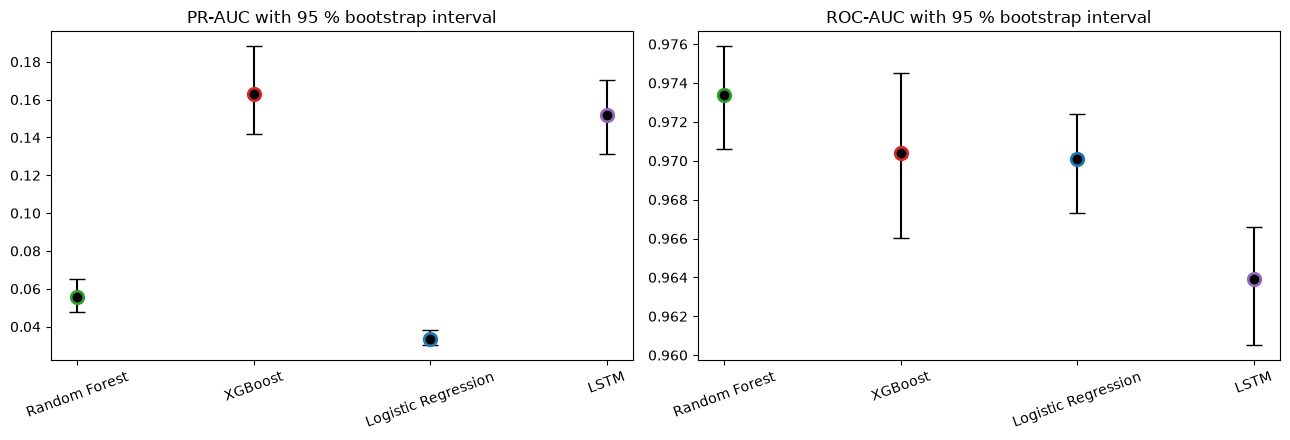

Share of resamples in which the ROW model has a higher PR-AUC than the COLUMN model (about 0.5 = cannot be told apart; near 1.0 = clearly better):


,Random Forest,XGBoost,Logistic Regression,LSTM
Random Forest,NaN,0.000000,1.000000,0.000000
XGBoost,1.000000,NaN,1.000000,0.870000
Logistic Regression,0.000000,0.000000,NaN,0.000000
LSTM,1.000000,0.130000,1.000000,NaN


In [10]:
if RUN_BOOTSTRAP:
    rng = np.random.default_rng(RANDOM_STATE)
    pos_i, neg_i = np.where(y == 1)[0], np.where(y == 0)[0]
    boot = {nm: {"PR-AUC": [], "ROC-AUC": []} for nm in MODEL_NAMES}
    t0 = time.time()
    for b in range(N_BOOT):                      # SAME resample for every model -> paired comparison
        idx = np.concatenate([rng.choice(pos_i, len(pos_i)), rng.choice(neg_i, len(neg_i))])
        yy = y[idx]
        for nm in MODEL_NAMES:
            s = scores[nm][idx]
            boot[nm]["PR-AUC"].append(average_precision_score(yy, s)); boot[nm]["ROC-AUC"].append(roc_auc_score(yy, s))
        if b == 0: print(f"first resample took {time.time() - t0:.0f}s -> about {(time.time() - t0) * N_BOOT / 60:.1f} min in total")
    ci = pd.DataFrame({nm: {"PR-AUC": ranking.set_index('Model').loc[nm, "PR-AUC"],
                            "PR-AUC 95% CI low": np.percentile(boot[nm]["PR-AUC"], 2.5), "PR-AUC 95% CI high": np.percentile(boot[nm]["PR-AUC"], 97.5),
                            "ROC-AUC": ranking.set_index('Model').loc[nm, "ROC-AUC"],
                            "ROC-AUC 95% CI low": np.percentile(boot[nm]["ROC-AUC"], 2.5), "ROC-AUC 95% CI high": np.percentile(boot[nm]["ROC-AUC"], 97.5)} for nm in MODEL_NAMES}).T
    print(f"Bootstrap ({N_BOOT} resamples of the test set):"); display(ci)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, m in zip(axes, ["PR-AUC", "ROC-AUC"]):
        mids = ci[m].to_numpy(); lo = mids - ci[f"{m} 95% CI low"].to_numpy(); hi = ci[f"{m} 95% CI high"].to_numpy() - mids
        ax.errorbar(range(len(MODEL_NAMES)), mids, yerr=[np.clip(lo, 0, None), np.clip(hi, 0, None)], fmt="o", capsize=6, color="black")
        for i, nm in enumerate(MODEL_NAMES): ax.plot(i, mids[i], "o", color=COLORS[nm], markersize=10)
        ax.set_xticks(range(len(MODEL_NAMES))); ax.set_xticklabels(MODEL_NAMES, rotation=20); ax.set_title(f"{m} with 95 % bootstrap interval")
    fig.tight_layout(); fig.savefig(RESULTS_DIR / "baseline_comparison_bootstrap_ci.png", dpi=150); plt.show()
    pw = pd.DataFrame(index=MODEL_NAMES, columns=MODEL_NAMES, dtype=float)
    for a in MODEL_NAMES:
        for b_ in MODEL_NAMES:
            pw.loc[a, b_] = np.mean(np.array(boot[a]["PR-AUC"]) > np.array(boot[b_]["PR-AUC"])) if a != b_ else np.nan
    print("Share of resamples in which the ROW model has a higher PR-AUC than the COLUMN model (about 0.5 = cannot be told apart; near 1.0 = clearly better):")
    display(pw)
    ci.to_csv(RESULTS_DIR / "baseline_comparison_bootstrap_ci.csv")
else:
    print("RUN_BOOTSTRAP = False - skipped")

In [11]:
rk = ranking.set_index("Model")
card = pd.DataFrame({
    "PR-AUC": rk["PR-AUC"], "ROC-AUC": rk["ROC-AUC"], "Best F1 (any threshold)": rk["Best F1 (any threshold)"],
    "F1 @0.50": at50["F1-Score"], "Recall @0.50": at50["Recall"], "Precision @0.50": at50["Precision"], "MCC @0.50": at50["MCC"],
    "Recall @ top 1.0%": rk["Recall @ top 1.0%"] if "Recall @ top 1.0%" in rk else np.nan,
}).loc[MODEL_NAMES]
ranks = card.rank(ascending=False, method="min")
card["Average rank (1 = best)"] = ranks.mean(axis=1)
card["Meets BOTH targets at any of the 5 thresholds"] = [bool(sweep[(sweep["Model"] == nm)]["Meets both targets"].any()) for nm in MODEL_NAMES]
card = card.sort_values("Average rank (1 = best)")
print("SCORECARD (sorted by average rank over the metrics shown):")
display(card)
card.to_csv(RESULTS_DIR / "baseline_comparison_summary.csv")
ranking.to_csv(RESULTS_DIR / "baseline_comparison_ranking_metrics.csv", index=False)

best_pr = rk["PR-AUC"].idxmax(); best_roc = rk["ROC-AUC"].idxmax(); best_f1 = rk["Best F1 (any threshold)"].idxmax()
print("=" * 90)
print(f"Highest PR-AUC (most important here): {best_pr} ({rk.loc[best_pr, 'PR-AUC']:.4f}; no-skill {prevalence:.5f}; lift x{rk.loc[best_pr, 'PR-AUC lift vs no-skill']:.1f})")
print(f"Highest ROC-AUC                      : {best_roc} ({rk.loc[best_roc, 'ROC-AUC']:.4f})")
print(f"Highest achievable F1                : {best_f1} ({rk.loc[best_f1, 'Best F1 (any threshold)']:.4f} at threshold {rk.loc[best_f1, 'Threshold of best F1']:.3f})")
col = f"Best precision at recall >= {TARGET_RECALL:.0%}"
best_target = rk[col].idxmax() if rk[col].notna().any() else None
if best_target is not None:
    v = rk.loc[best_target, col]
    print(f"Best precision while keeping recall >= {TARGET_RECALL:.0%}: {best_target} ({v:.4f}) -> project target precision >= {TARGET_PRECISION:.0%} is "
          + ("REACHABLE by at least one model" if v >= TARGET_PRECISION else "NOT reachable by any model at any threshold"))
else:
    print(f"No model reaches recall >= {TARGET_RECALL:.0%} at any threshold.")
print("=" * 90)

SCORECARD (sorted by average rank over the metrics shown):


,PR-AUC,ROC-AUC,Best F1 (any threshold),F1 @0.50,Recall @0.50,Precision @0.50,MCC @0.50,Recall @ top 1.0%,Average rank (1 = best),Meets BOTH targets at any of the 5 thresholds
Model,,,,,,,,,,
XGBoost,0.163093,0.970416,0.220994,0.085330,0.675676,0.045541,0.173764,0.675676,1.500000,False
Random Forest,0.055739,0.973369,0.124671,0.073548,0.576216,0.039281,0.148668,0.580541,2.375000,False
LSTM,0.151973,0.963927,0.227701,0.007386,0.985946,0.003707,0.054672,0.496216,3.000000,False
Logistic Regression,0.033301,0.970093,0.093458,0.009501,0.972973,0.004774,0.063089,0.497297,3.125000,False


Highest PR-AUC (most important here): XGBoost (0.1631; no-skill 0.00067; lift x244.2)
Highest ROC-AUC                      : Random Forest (0.9734)
Highest achievable F1                : LSTM (0.2277 at threshold 0.996)
Best precision while keeping recall >= 80%: XGBoost (0.0140) -> project target precision >= 20% is NOT reachable by any model at any threshold
